# Разведочный анализ данных: продолжение

**Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
Дисциплина «Разведочный анализ и алгоритмы классификации» (Барулина М. А.), практика «Разведочный анализ данных: продолжение».

Текст и код преподавателя сохранены. Мои решения записаны в ячейки с «# your code here», после каждого задания идёт блок **«Ответ»** с пояснением. Кроме того, я добавил короткие наблюдения после тепловых карт, V Крамера и ANOVA. На этапе EDA я описываю только то, что видно в данных, без выводов о причинах.

**Что поправлено, чтобы тетрадка работала вне Colab (Python 3.13, pandas 3, polars 2):**

1. Данные взяты по той же ссылке на GitHub; локальную копию `../data/diamonds_clean.csv` кладёт скрипт `scripts/download_data.py`. Если файла нет, тетрадка прочитает его по URL.
2. `df.corr()` заменено на `df.corr(numeric_only=True)`. Начиная с pandas 2.0 `corr` больше не отбрасывает текстовые столбцы молча и падает с `ValueError: could not convert string to float: 'Ideal'`.
3. Пакет `association-metrics` (версия 0.0.1, 2021 г.) не работает с pandas 3, поэтому заменён своей функцией V Крамера на `scipy` с той же формулой (χ² без поправки Йейтса). Проблем у пакета две. Во-первых, текстовые столбцы теперь имеют тип `str`, а не `object`, условие `x.dtype == "object"` ложно, категорий не находится, и вызов падает с `KeyError: No categorical variables found`. Во-вторых, даже с категориями пакет заполняет матрицу цепочкой `self.matrix[x][y] = value`, а при Copy-on-Write это не меняет таблицу, и матрица остаётся нулевой.
4. В цикле ANOVA проверка `df[c].dtype == 'object'` заменена на `pd.api.types.is_string_dtype` / `is_numeric_dtype` по той же причине. Иначе цикл не находит ни одной пары и возвращает пустую таблицу.
5. Polars 2.0: `groupby` → `group_by` (переименовано ещё в 0.19), `collect(streaming=True)` → `collect(engine="streaming")` (аргумент удалён в 2.0). Вместо `!pip install polars` теперь импорт с понятной ошибкой, а сам `polars` добавлен в `requirements.txt`.
6. `%%time` должен стоять первой строкой ячейки. Там, где перед ним был комментарий («# Pandas», «# Polars», «# lazy operations», «# your code here»), IPython выдаёт `UsageError: Line magic function %%time not found`, поэтому комментарий перенесён под `%%time`.
7. Файл `diamonds_big.csv` (около 140 МБ) записывается в `../data/` и внесён в `.gitignore`. В репозиторий он не кладётся, а создаётся при запуске тетрадки.
8. Перед разделом про машинное обучение `df` возвращается к исходным 53 805 строкам. После раздела Polars в `df` лежала 51-кратная таблица. Коэффициенты регрессии и MAE от этого не меняются (это проверено ниже), а графики строятся быстрее.

Мы будем работать с датасетом про алмазы - в нем содержатся их различные характеристики, а также стоимость.

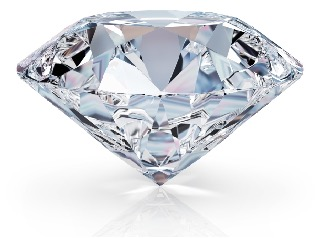

## Импорт библиотек и загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os

DIAMONDS_URL = "https://raw.githubusercontent.com/aiedu-courses/stepik_eda_and_dev_tools/main/datasets/diamonds_clean.csv"
DIAMONDS_DATASET = "../data/diamonds_clean.csv"      # локальная копия файла по ссылке выше

if not os.path.exists(DIAMONDS_DATASET):            # если копии нет — читаем напрямую с GitHub
    DIAMONDS_DATASET = DIAMONDS_URL

In [3]:
df = pd.read_csv(DIAMONDS_DATASET)

## Описание данных

* `carat` - число каратов алмаза
* `cut` - огранка алмаза
* `color` - цвет алмаза
* `clarity` - прозрачность алмаза
* `depth` - глубина алмаза
* `table` - платформа алмаза (грань, которую можно увидеть, если смотреть на камень лицевой стороной вверх)
* `price` - цена алмаза
* `x` - размер алмаза по оси x
* `y` - размер алмаза по оси y
* `z` - размер алмаза по оси z

In [4]:
df.head()

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335.0,4.34,4.35,2.75


## Исследование данных

Размер датасета

In [5]:
df.shape

(53805, 10)

Информация о типах данных и пропусках

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53805 entries, 0 to 53804
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53805 non-null  float64
 1   cut      53805 non-null  str    
 2   color    53805 non-null  str    
 3   clarity  53805 non-null  str    
 4   depth    53805 non-null  float64
 5   table    53805 non-null  float64
 6   price    53805 non-null  float64
 7   'x'      53805 non-null  float64
 8   'y'      53805 non-null  float64
 9   'z'      53805 non-null  float64
dtypes: float64(7), str(3)
memory usage: 4.1 MB


## Взаимозависимость в данных

### 1. Корреляция

**Корреляция Пирсона**

pearson.svg

Корреляция Пирсона - это мера линейной взаимосвязи двух числовых столбцов.

* $r$	=	correlation coefficient
* $x_{i}$	=	values of the x-variable in a sample
* $\bar{x}$	=	mean of the values of the x-variable
* $y_{i}$	=	values of the y-variable in a sample
* $\bar{y}$	=	mean of the values of the y-variable

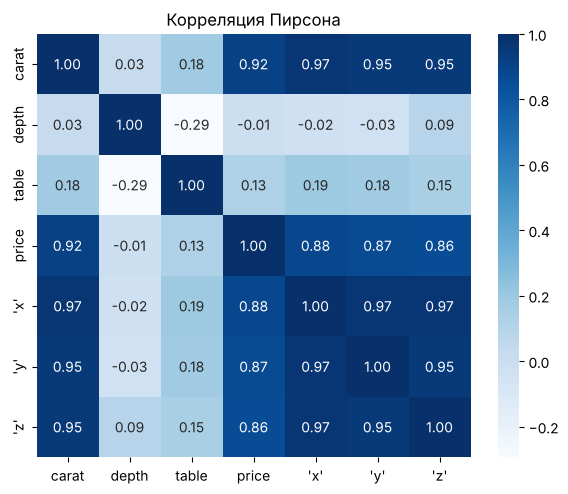

In [7]:
corr = df.corr(numeric_only=True) # матрица корреляций (в Colab: df.corr() — в pandas ≥ 2 падает на текстовых столбцах)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, cmap="Blues", annot=True, fmt='.2f')
plt.title('Корреляция Пирсона');

*Наблюдение.* `carat`, `price`, `x`, `y`, `z` образуют плотный блок: коэффициенты Пирсона между ними от 0.86 до 0.97. `depth` и `table` почти не коррелируют ни с чем, кроме друг друга (r = −0.29). Поскольку размеры и вес коррелируют на уровне 0.95–0.97, это по сути почти одна и та же информация о величине камня.

**Корреляция Спирмена**

Коэффициент корреляции Спирмена основан на ранжировании значений переменных и измеряет степень монотонной связи между ними.

Значение коэффициента корреляции Спирмена лежит в диапазоне от -1 до 1. Значение -1 означает полную отрицательную связь (чем больше одна переменная, тем меньше другая), значение 1 означает положительную связь (чем больше одна переменная, тем больше другая), а значение 0 означает отсутствие связи между переменными.

Можно использовать для порядковых переменных!

spearman.svg

* $\rho$	=	Spearman's rank correlation coefficient
* $d_{i}$	=	difference between the two ranks of each observation
* $n$	=	number of observations

[Пример расчета коэффициента корреляции Спирмена](https://statpsy.ru/spearman/primer-raschet-spearman/)

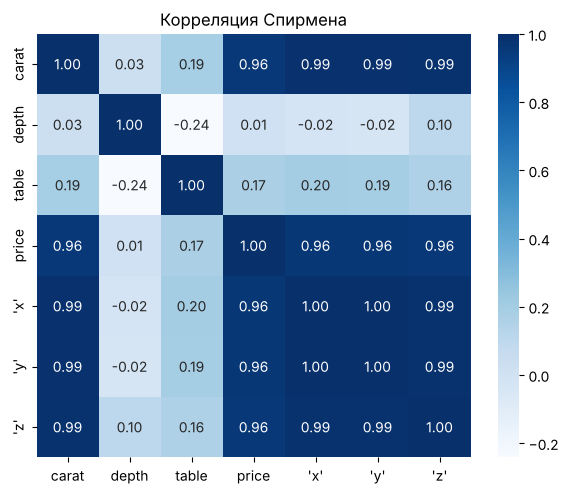

In [8]:
corr = df.corr(method='spearman', numeric_only=True)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, cmap="Blues", annot=True, fmt='.2f')
plt.title('Корреляция Спирмена');

*Наблюдение.* По Спирмену блок «вес — размеры — цена» ещё плотнее: 0.96–1.00, корреляция `carat` с `price` 0.96 против 0.92 у Пирсона. Спирмен смотрит на монотонность, а не на линейность, поэтому рост выше. Цена растёт с весом монотонно, но не по прямой, что было видно и в первой практике.

**Корреляция Кендалла**

Чаще используется для пары номинальный - номинальный признак.

Похожа на корреляцию Спирмена.

### Задание 1

Вычислите матрицу корреляций, используя корреляцию Кендалла.

С каким столбцом коррелирует в этой матрице `depth` больше всего?

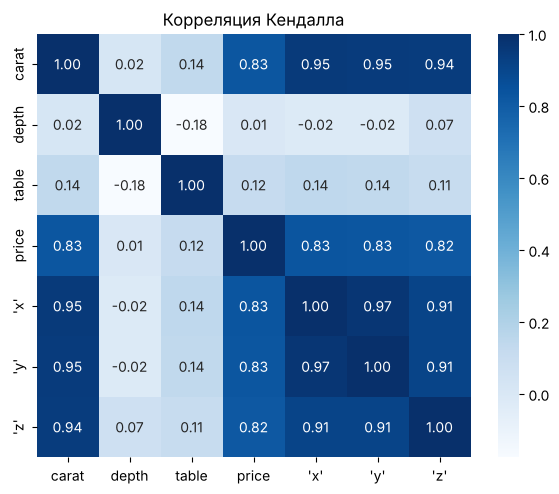

table   -0.1765
'y'     -0.0186
'x'     -0.0172
price    0.0061
carat    0.0208
'z'      0.0707
Name: depth, dtype: float64
Сильнее всего (по модулю) depth коррелирует с: table


In [9]:
corr_kendall = df.corr(method='kendall', numeric_only=True)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_kendall, cmap="Blues", annot=True, fmt='.2f')
plt.title('Корреляция Кендалла')
plt.show()

depth_corr = corr_kendall['depth'].drop('depth')
print(depth_corr.round(4).sort_values())
print('Сильнее всего (по модулю) depth коррелирует с:', depth_corr.abs().idxmax())

**Ответ: с `table`** (τ = −0.177, если сравнивать по модулю). Если учитывать только положительные значения, то максимум у `'z'` (τ = 0.071). Обе связи слабые.

Сила связи определяется модулем коэффициента, знак показывает только направление. Поэтому ответом я считаю `table`: камни с большим `depth` в этих данных в среднем имеют чуть меньший `table`. Абсолютные значения τ Кендалла меньше, чем ρ Спирмена, это нормально для этого коэффициента, но порядок признаков почти тот же.

*Замечание.* τ Кендалла, как и ρ Спирмена, ранговый коэффициент, он применим к числовым и **порядковым** признакам. Для пар номинальных признаков используется V Крамера из следующего раздела.

### 2. V-мера Крамера

*Для измерения связи между Категориальным - Категориальным признаком*

Для оценки степени взаимосвязи категориальных столбцов можно вычислять V-меру Крамера.
Это вариант нормировки статистики $\chi^2$. Статистика $\chi^2$ - это функция, измеряющая меру взаимосвязи двух категориальных переменных.

Пусть $X, Y$ - две категориальных переменных, тогда $\chi^2$ вычисляется по формуле

$$\chi^2(X,Y)=\sum_{i,j}\frac{(O_{ij}-E_{ij})^2}{E_{ij}},$$

где $O_{ij}$ - наблюдаемая частота события, $E_{ij}$ - ожидаемая частота события (в предположении, что величины $X$ и $Y$ независимы).

Чем больше значение $\chi^2$ - тем больше степень взаимосвязи переменных $X$ и $Y$.



**Покажем на примере.**

Изучим по некоторым данным зависимость факта курения и повышенного давления. По данным составим таблицу сопряженности.

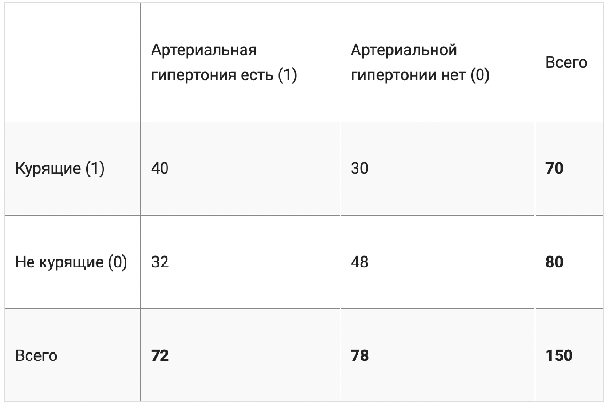

Вычисляем $\chi^2$:

$O_{11} = 40$

$E_{11} = 70 * 72 / 150 \approx 33.6 $ (так считается $E_{ij}$, если величины независимы)

Аналогично вычисляются оставшиеся слагаемые в формуле. Получаем

$\chi^2(X,Y) = (40-33.6)^2/33.6 + (30-36.4)^2/36.4 + (32-38.4)^2/38.4 + (48-41.6)^2/41.6 = 4.396$



Чем больше $\chi^2$, тем больше взаимосвязь между признаками.

В случае, если признаки независимы, то ожидаемая и наблюдаемая частоты совпадут, и $\chi^2=0$.



V-мера Крамера - это нормировка $\chi^2$ на число значений в каждой категории:

$$V = \sqrt{\frac{\chi^2/n}{min(k-1,r-1)}},$$

где


$n$ - общее число наблюдений

$k$ - число категорий в $X$

$r$ - число категорий в $Y$


В результате этой нормировки V-мера находится на отрезке от 0 до 1 и легко интерпретируется: *чем больше V-мера - тем больше зависимость между двумя переменными, и наоборот.*

In [10]:
# В Colab: !pip install association-metrics -q
# Пакет association-metrics 0.0.1 не работает с pandas 3 (см. пункт 3 в начале тетрадки),
# поэтому та же мера реализована на scipy: χ² без поправки Йейтса, V = sqrt(χ²/n / (min(k, r) − 1)).
from scipy.stats import chi2_contingency

# проверка на примере из текста (курение × давление): χ² должно быть ≈ 4.396
print('χ² для примера:', round(chi2_contingency([[40, 30], [32, 48]], correction=False)[0], 3))

χ² для примера: 4.396


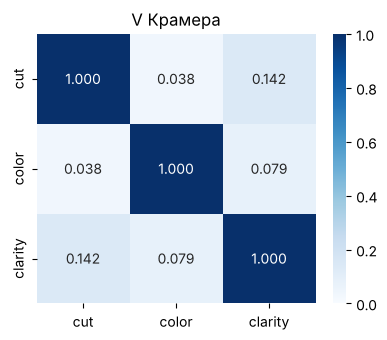

,cut,color,clarity
cut,1.000000,0.037724,0.142217
color,0.037724,1.000000,0.079487
clarity,0.142217,0.079487,1.000000


In [11]:
def cramers_v(x, y):
    # V Крамера для двух категориальных столбцов — та же формула, что в association_metrics.CramersV
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / n / (min(table.shape) - 1))

cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]   # в Colab: dtype == "object"
cramersv = pd.DataFrame([[cramers_v(df[a], df[b]) for b in cat_cols] for a in cat_cols],
                        index=cat_cols, columns=cat_cols)

plt.figure(figsize=(4.5, 3.5))
sns.heatmap(cramersv, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=1)
plt.title('V Крамера')
plt.show()
cramersv

*Наблюдение.* Попарная связь между `cut`, `color` и `clarity` слабая: V от 0.04 (`cut`–`color`) до 0.14 (`cut`–`clarity`). Значит, эти три характеристики в данных почти независимы друг от друга, и по одной категории трудно угадать другую. Все три признака на самом деле порядковые (от худшей градации к лучшей). V Крамера порядок не учитывает, и это мера для номинальной связи «любого вида».

### 3. ANOVA

*Для измерения связи между Числовым - Категориальным признаком*

ANOVA (англ. Analysis of Variance) - это статистический метод, используемый для сравнения средних значений между тремя и более группами. ANOVA анализирует различия между средними значениями внутри групп и между группами, чтобы определить, есть ли статистически значимые различия между ними.

ANOVA основан на предположении, что переменная, которая анализируется, является нормально распределенной в каждой группе, и что дисперсия внутри групп равномерна. В результате, ANOVA проверяет, насколько различны средние значения между группами по сравнению со случайной вариацией внутри групп.

ANOVA производит F-тест, который сравнивает дисперсию между группами с дисперсией внутри групп. Если различия между группами значительны по сравнению со случайной вариацией внутри групп, то F-тест покажет статистически значимый результат, указывающий на наличие различий между группами.

In [12]:
# Generating sample data
import pandas as pd
ColumnNames=['FuelType','CarPrice']
DataValues= [
             [  'Petrol',   2000],
             [  'Petrol',   2100],
             [  'Petrol',   1900],
             [  'Petrol',   2150],
             [  'Petrol',   2100],
             [  'Petrol',   2200],
             [  'Petrol',   1950],
             [  'Diesel',   2500],
             [  'Diesel',   2700],
             [  'Diesel',   2900],
             [  'Diesel',   2850],
             [  'Diesel',   2600],
             [  'Diesel',   2500],
             [  'Diesel',   2700],
             [  'CNG',   1500],
             [  'CNG',   1400],
             [  'CNG',   1600],
             [  'CNG',   1650],
             [  'CNG',   1600],
             [  'CNG',   1500],
             [  'CNG',   1500]
           ]
#Create the Data Frame
CarData=pd.DataFrame(data=DataValues,columns=ColumnNames)

########################################################
# f_oneway() function takes the group data as input and
# returns F-statistic and P-value

from scipy.stats import f_oneway

# Running the one-way anova test between CarPrice and FuelTypes
# Assumption(H0) is that FuelType and CarPrices are NOT correlated

# Finds out the Prices data for each FuelType as a list

CategoryGroupLists = CarData.groupby('FuelType')['CarPrice'].apply(list)

# Performing the ANOVA test
# We accept the Assumption(H0) only when P-Value >= 0.05

AnovaResults = f_oneway(*CategoryGroupLists)

print('P-Value for Anova is: ', AnovaResults[1])

if AnovaResults[1] >= 0.05:
    print('Features are NOT correlated')
else:
    print('Features are correlated')

P-Value for Anova is:  4.3558466424602e-12
Features are correlated


In [13]:
Data = []

for c1 in df.columns:
    for c2 in df.columns:
        # в Colab: df[c1].dtype == 'object' and df[c2].dtype != 'object' — в pandas 3 текст имеет тип str
        if pd.api.types.is_string_dtype(df[c1]) and pd.api.types.is_numeric_dtype(df[c2]):
            CategoryGroupLists = df.groupby(c1)[c2].apply(list)
            AnovaResults = f_oneway(*CategoryGroupLists)

            if AnovaResults[1] >= 0.05:
                Data.append({'Category' : c1, 'Numerical' : c2, 'Is correlated' : 'No'})
            else:
                Data.append({'Category' : c1, 'Numerical' : c2, 'Is correlated' : 'Yes'})

AnovaRes = pd.DataFrame.from_dict(Data)
AnovaRes

,Category,Numerical,Is correlated
0,cut,carat,Yes
1,cut,depth,Yes
2,cut,table,Yes
3,cut,price,Yes
4,cut,'x',Yes
5,cut,'y',Yes
6,cut,'z',Yes
7,color,carat,Yes
8,color,depth,Yes
9,color,table,Yes


Все 21 пара получили «Yes». При 53 805 наблюдениях даже крошечная разница средних оказывается статистически значимой, а p-value говорит только о том, что средние в группах различаются, но не о том, насколько сильно. Поэтому дополню таблицу статистикой F и размером эффекта η² = SS<sub>между группами</sub> / SS<sub>общая</sub>, то есть долей разброса числового признака, которая приходится на различия между категориями.

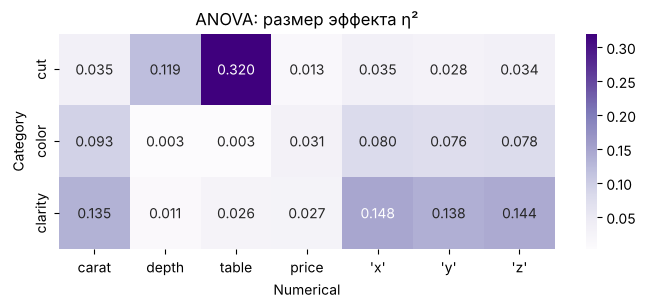

,Category,Numerical,F,p-value,eta2
2,cut,table,6333.8436,0.0,0.3202
18,clarity,'x',1334.3880,0.0,0.1479
20,clarity,'z',1289.4125,0.0,0.1437
19,clarity,'y',1225.6056,0.0,0.1375
14,clarity,carat,1198.5397,0.0,0.1349
1,cut,depth,1825.3473,0.0,0.1195


In [14]:
num_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
rows = []
for c1 in cat_cols:
    for c2 in num_cols:
        groups = [g.to_numpy() for _, g in df.groupby(c1)[c2]]
        F, p = f_oneway(*groups)
        grand = df[c2].mean()
        eta2 = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((df[c2] - grand) ** 2).sum()
        rows.append({'Category': c1, 'Numerical': c2, 'F': F, 'p-value': p, 'eta2': eta2})
anova_full = pd.DataFrame(rows)

plt.figure(figsize=(8, 2.8))
sns.heatmap(anova_full.pivot(index='Category', columns='Numerical', values='eta2').reindex(index=cat_cols, columns=num_cols),
            annot=True, fmt='.3f', cmap='Purples')
plt.title('ANOVA: размер эффекта η²')
plt.show()
anova_full.sort_values('eta2', ascending=False).head(6).round(4)

*Наблюдение.* Самая заметная разница средних у пары `cut` → `table` (η² = 0.32), дальше идут `clarity` → размеры и вес (≈ 0.13–0.15) и `cut` → `depth` (0.12). Для цены η² маленький: 0.013 по `cut`, 0.027 по `clarity`, 0.031 по `color`, то есть разбиение на категории объясняет лишь несколько процентов разброса цены. Связь `cut` с `table` и `depth` ожидаема, ведь огранку и оценивают по пропорциям. Стоит помнить и про допущения ANOVA (нормальность в группах, равные дисперсии): для цены с её тяжёлым правым хвостом они не выполняются, так что p-value здесь ориентировочные.

## Polars

В конце 2020 года в python стала доступна библиотека Polars.

Polars - это высокопроизводительная библиотека для манипуляции и анализа данных в Python и Rust. Она была создана как альтернатива Pandas, но с учетом возможностей параллельной обработки данных на многопроцессорных системах.

Одним из основных преимуществ Polars является его скорость работы с данными. Polars использует многопоточную обработку данных, что позволяет обрабатывать большие объемы данных на многопроцессорных системах в несколько раз быстрее, чем Pandas. Кроме того, Polars имеет более эффективную систему памяти, что позволяет работать с данными, которые не помещаются в оперативной памяти.


Хорошая [статья про сравнение Pandas и Polars](https://vc.ru/u/1389654-machine-learning/583603-pandas-vs-polars-sravnenie-sintaksisa-i-skorosti)

In [15]:
BIG_CSV = "../data/diamonds_big.csv"   # ≈140 МБ; создаётся здесь, в репозиторий не кладётся (.gitignore)

df_big = df.copy()

for i in range(50):
  df_big = pd.concat([df_big, df])

df_big.to_csv(BIG_CSV, index=False)

In [16]:
df_big.shape, df.shape

((2744055, 10), (53805, 10))

In [17]:
# В Colab: !pip install polars
try:
    import polars as pl
except ImportError as err:
    raise ImportError('Нужен пакет polars: pip install -r requirements.txt (или pip install polars)') from err

print(pl.__version__)

2.0.0


### Загрузка данных

In [18]:
%%time

df_pl = pl.read_csv(BIG_CSV)

CPU times: user 1.35 s, sys: 437 ms, total: 1.78 s
Wall time: 1.28 s


In [19]:
%%time

df = pd.read_csv(BIG_CSV)

CPU times: user 1.96 s, sys: 395 ms, total: 2.35 s
Wall time: 2.52 s


### Выбор и фильтрация данных

In [20]:
df.head()

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,Ideal,E,SI2,61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335.0,4.34,4.35,2.75


In [21]:
%%time

df[['carat', 'depth']]

CPU times: user 1.27 ms, sys: 0 ns, total: 1.27 ms
Wall time: 1.26 ms


,carat,depth
0,0.23,61.5
1,0.21,59.8
2,0.23,56.9
3,0.29,62.4
4,0.31,63.3
...,...,...
2744050,0.72,60.8
2744051,0.72,63.1
2744052,0.70,62.8
2744053,0.86,61.0


In [22]:
%%time

df_pl[['carat', 'depth']]

# df_pl.select(pl.col(['carat', 'depth']))

CPU times: user 377 μs, sys: 49 μs, total: 426 μs
Wall time: 415 μs


carat,depth
f64,f64
0.23,61.5
0.21,59.8
0.23,56.9
0.29,62.4
0.31,63.3
…,…
0.72,60.8
0.72,63.1
0.7,62.8


In [23]:
%%time
# Pandas  (в Colab комментарий стоял над %%time — так ячейка падает с UsageError)

df.query('carat > 5')

CPU times: user 31 ms, sys: 23.1 ms, total: 54 ms
Wall time: 54.8 ms


,carat,cut,color,clarity,depth,table,price,'x','y','z'
27355,5.01,Fair,J,I1,65.5,59.0,18018.0,10.74,10.54,6.98
81160,5.01,Fair,J,I1,65.5,59.0,18018.0,10.74,10.54,6.98
134965,5.01,Fair,J,I1,65.5,59.0,18018.0,10.74,10.54,6.98
188770,5.01,Fair,J,I1,65.5,59.0,18018.0,10.74,10.54,6.98
242575,5.01,Fair,J,I1,65.5,59.0,18018.0,10.74,10.54,6.98
296380,5.01,Fair,J,I1,65.5,59.0,18018.0,10.74,10.54,6.98
350185,5.01,Fair,J,I1,65.5,59.0,18018.0,10.74,10.54,6.98
403990,5.01,Fair,J,I1,65.5,59.0,18018.0,10.74,10.54,6.98
457795,5.01,Fair,J,I1,65.5,59.0,18018.0,10.74,10.54,6.98
511600,5.01,Fair,J,I1,65.5,59.0,18018.0,10.74,10.54,6.98


In [24]:
%%time
# Polars

df_pl.filter(pl.col('carat') > 5)

CPU times: user 10.9 ms, sys: 0 ns, total: 10.9 ms
Wall time: 7.98 ms


carat,cut,color,clarity,depth,table,price,'x','y','z'
f64,str,str,str,f64,f64,f64,f64,f64,f64
5.01,"""Fair""","""J""","""I1""",65.5,59.0,18018.0,10.74,10.54,6.98
5.01,"""Fair""","""J""","""I1""",65.5,59.0,18018.0,10.74,10.54,6.98
5.01,"""Fair""","""J""","""I1""",65.5,59.0,18018.0,10.74,10.54,6.98
5.01,"""Fair""","""J""","""I1""",65.5,59.0,18018.0,10.74,10.54,6.98
5.01,"""Fair""","""J""","""I1""",65.5,59.0,18018.0,10.74,10.54,6.98
…,…,…,…,…,…,…,…,…,…
5.01,"""Fair""","""J""","""I1""",65.5,59.0,18018.0,10.74,10.54,6.98
5.01,"""Fair""","""J""","""I1""",65.5,59.0,18018.0,10.74,10.54,6.98
5.01,"""Fair""","""J""","""I1""",65.5,59.0,18018.0,10.74,10.54,6.98


### Задание 2

С помощью polars и pandas отфильтруйте таблицу, оставив в ней только строки, удовлетворяющие условиям:
* `color` = "J"
* `price` > 1000

Сравните время выполнения запросов

In [25]:
%%time
# your code here  (Pandas)

df[(df.color == 'J') & (df.price > 1000)]

CPU times: user 232 ms, sys: 12.1 ms, total: 244 ms
Wall time: 248 ms


,carat,cut,color,clarity,depth,table,price,'x','y','z'
172,1.17,Very Good,J,I1,60.2,61.0,2774.0,6.83,6.90,4.13
247,1.05,Very Good,J,SI2,63.2,56.0,2789.0,6.49,6.45,4.09
255,1.05,Fair,J,SI2,65.8,59.0,2789.0,6.41,6.27,4.18
324,1.00,Premium,J,SI2,62.3,58.0,2801.0,6.45,6.34,3.98
366,0.93,Premium,J,SI2,61.9,57.0,2807.0,6.21,6.19,3.84
...,...,...,...,...,...,...,...,...,...,...
2743817,0.90,Good,J,SI2,63.9,56.0,2717.0,6.17,6.10,3.92
2743902,0.90,Good,J,SI1,63.2,60.0,2729.0,6.09,6.12,3.86
2743963,0.82,Ideal,J,VS2,61.6,56.0,2741.0,6.00,6.04,3.71
2743967,0.83,Ideal,J,VS2,62.3,55.0,2742.0,6.01,6.03,3.75


In [26]:
%%time

df_pl.filter((pl.col('color') == 'J') & (pl.col('price') > 1000))

CPU times: user 44.4 ms, sys: 15 ms, total: 59.4 ms
Wall time: 34.7 ms


carat,cut,color,clarity,depth,table,price,'x','y','z'
f64,str,str,str,f64,f64,f64,f64,f64,f64
1.17,"""Very Good""","""J""","""I1""",60.2,61.0,2774.0,6.83,6.9,4.13
1.05,"""Very Good""","""J""","""SI2""",63.2,56.0,2789.0,6.49,6.45,4.09
1.05,"""Fair""","""J""","""SI2""",65.8,59.0,2789.0,6.41,6.27,4.18
1.0,"""Premium""","""J""","""SI2""",62.3,58.0,2801.0,6.45,6.34,3.98
0.93,"""Premium""","""J""","""SI2""",61.9,57.0,2807.0,6.21,6.19,3.84
…,…,…,…,…,…,…,…,…,…
0.9,"""Good""","""J""","""SI2""",63.9,56.0,2717.0,6.17,6.1,3.92
0.9,"""Good""","""J""","""SI1""",63.2,60.0,2729.0,6.09,6.12,3.86
0.82,"""Ideal""","""J""","""VS2""",61.6,56.0,2741.0,6.0,6.04,3.71


Строк после фильтрации: pandas 119493 | polars 119493


Фильтрация: pandas 194.7 мс, polars 22.5 мс — polars быстрее в 8.7 раза


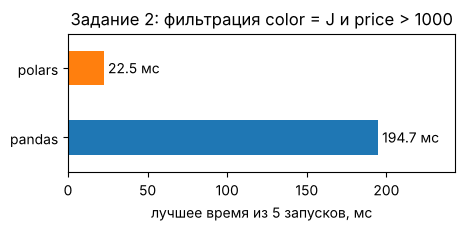

In [27]:
import time

def best_time_ms(func, repeat=5):
    # минимальное время из нескольких запусков, мс: так меньше влияние случайных задержек
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        func()
        times.append(time.perf_counter() - t0)
    return 1000 * min(times)

n_pd = len(df[(df.color == 'J') & (df.price > 1000)])
n_pl = df_pl.filter((pl.col('color') == 'J') & (pl.col('price') > 1000)).height
print('Строк после фильтрации: pandas', n_pd, '| polars', n_pl)

t2_pd = best_time_ms(lambda: df[(df.color == 'J') & (df.price > 1000)])
t2_pl = best_time_ms(lambda: df_pl.filter((pl.col('color') == 'J') & (pl.col('price') > 1000)))
print(f'Фильтрация: pandas {t2_pd:.1f} мс, polars {t2_pl:.1f} мс — polars быстрее в {t2_pd / t2_pl:.1f} раза')

ax = pd.Series({'pandas': t2_pd, 'polars': t2_pl}).plot.barh(figsize=(5, 1.8), color=['tab:blue', 'tab:orange'])
ax.bar_label(ax.containers[0], fmt='%.1f мс', padding=3); ax.margins(x=0.25); ax.set_xlabel('лучшее время из 5 запусков, мс')
ax.set_title('Задание 2: фильтрация color = J и price > 1000'); plt.show()

**Ответ.** Обе библиотеки оставляют одинаковое число строк: 119 493 (это 2 343 исходных алмаза × 51 копия). Одиночные замеры `%%time` шумные (первый запуск включает «прогрев»), поэтому для сравнения я взял лучшее время из 5 повторов: pandas 194.7 мс, polars 22.5 мс, то есть polars быстрее примерно в 8.7 раза. Polars быстрее, потому что хранит столбцы в колоночном формате Apache Arrow и выполняет фильтр скомпилированным многопоточным кодом на Rust. В pandas без `pyarrow` строки лежат как объекты Python, и сравнение `color == 'J'` идёт по объектам. Абсолютные числа зависят от компьютера и его загрузки.

### Агрегация данных

In [28]:
df_pl.head()

carat,cut,color,clarity,depth,table,price,'x','y','z'
f64,str,str,str,f64,f64,f64,f64,f64,f64
0.23,"""Ideal""","""E""","""SI2""",61.5,55.0,326.0,3.95,3.98,2.43
0.21,"""Premium""","""E""","""SI1""",59.8,61.0,326.0,3.89,3.84,2.31
0.23,"""Good""","""E""","""VS1""",56.9,65.0,327.0,4.05,4.07,2.31
0.29,"""Premium""","""I""","""VS2""",62.4,58.0,334.0,4.2,4.23,2.63
0.31,"""Good""","""J""","""SI2""",63.3,58.0,335.0,4.34,4.35,2.75


In [29]:
%%time

df.groupby('cut').agg({'table' : 'mean', 'price' : 'max'})

CPU times: user 341 ms, sys: 31.9 ms, total: 373 ms
Wall time: 403 ms


,table,price
cut,,
Fair,59.064205,18574.0
Good,58.676450,18788.0
Ideal,55.952779,18806.0
Premium,58.747643,18823.0
Very Good,57.955712,18818.0


In [30]:
%%time

# в Colab: df_pl.groupby(...) — в polars ≥ 0.19 метод называется group_by
df_pl.group_by('cut').agg([pl.mean('table'), pl.max('price')])

CPU times: user 89.9 ms, sys: 140 μs, total: 90 ms
Wall time: 55.2 ms


cut,table,price
str,f64,f64
"""Ideal""",55.952779,18806.0
"""Premium""",58.747643,18823.0
"""Good""",58.67645,18788.0
"""Fair""",59.064205,18574.0
"""Very Good""",57.955712,18818.0


In [31]:
%%time
# lazy operations

q = (
    df_pl
    .lazy()
    .group_by('cut')        # в Colab: .groupby(by='cut')
    .agg(
        [
            pl.col('table').mean(),
            pl.col('price').max()
        ]
    )
)

CPU times: user 121 μs, sys: 15 μs, total: 136 μs
Wall time: 141 μs


In [32]:
%%time

q.collect()

CPU times: user 76.7 ms, sys: 785 μs, total: 77.5 ms
Wall time: 41.6 ms


cut,table,price
str,f64,f64
"""Ideal""",55.952779,18806.0
"""Premium""",58.747643,18823.0
"""Good""",58.67645,18788.0
"""Very Good""",57.955712,18818.0
"""Fair""",59.064205,18574.0


### Задание 3

Для каждого цвета (`color`) вычислите медианную стоимость алмазов и средний вес (`carat`).

* Сначала напишите eager-запрос в стиле, приближенном к pandas.

* Затем напишите lazy-запрос в polars-стиле. После этого выполните запрос методом collect.

* Сравните время выполнения запросов.



In [33]:
%%time
# pandas — для сравнения
color_pd = (df.groupby('color')
              .agg(PriceMedian=('price', 'median'), CaratMean=('carat', 'mean'))
              .sort_index())

CPU times: user 296 ms, sys: 47.9 ms, total: 343 ms
Wall time: 343 ms


In [34]:
%%time
# polars, eager-запрос в стиле pandas: выполняется сразу над DataFrame
color_eager = (df_pl.group_by('color')
                    .agg([pl.median('price').alias('PriceMedian'), pl.mean('carat').alias('CaratMean')])
                    .sort('color'))

CPU times: user 174 ms, sys: 301 ms, total: 475 ms
Wall time: 279 ms


In [35]:
%%time
# polars, lazy-запрос: строится только план, данные не трогаются
q_color = (
    df_pl
    .lazy()
    .group_by('color')
    .agg(
        [
            pl.col('price').median().alias('PriceMedian'),
            pl.col('carat').mean().alias('CaratMean'),
        ]
    )
    .sort('color')
)

CPU times: user 115 μs, sys: 15 μs, total: 130 μs
Wall time: 134 μs


In [36]:
%%time

color_lazy = q_color.collect()

CPU times: user 168 ms, sys: 4.26 ms, total: 172 ms
Wall time: 93.6 ms


Результаты совпадают: True


color,PriceMedian,CaratMean
str,f64,f64
"""D""",1842.0,0.658697
"""E""",1741.0,0.657815
"""F""",2345.0,0.736323
"""G""",2246.0,0.770161
"""H""",3453.5,0.909103
"""I""",3723.0,1.020684
"""J""",4234.5,1.15934


pandas groupby            337.6 мс
polars eager              164.9 мс
polars lazy + collect     111.5 мс
polars lazy быстрее pandas в 3.0 раза, eager — в 2.0 раза


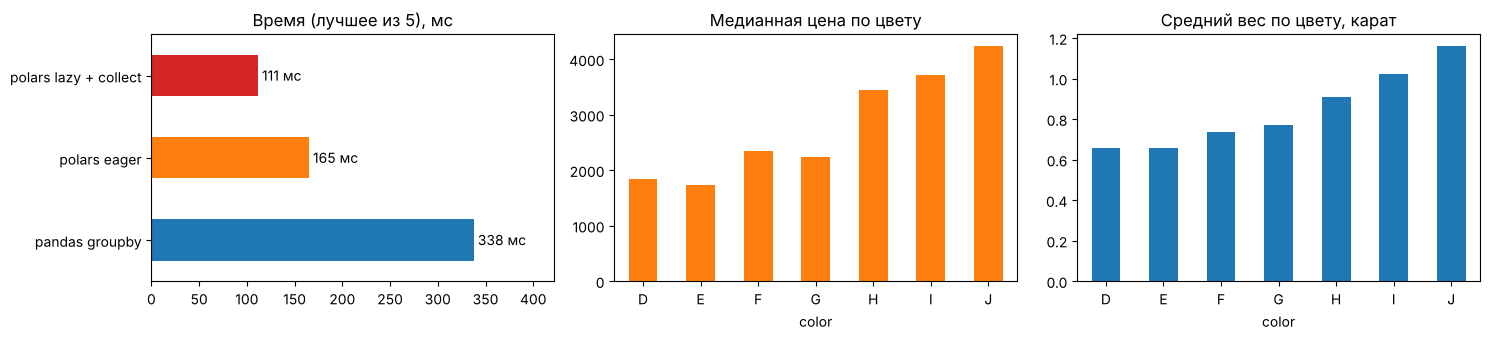

In [37]:
# все три способа дают одну и ту же таблицу
same = all(np.allclose(color_pd[col].to_numpy(), other[col].to_numpy())
           for other in (color_eager, color_lazy) for col in ('PriceMedian', 'CaratMean'))
print('Результаты совпадают:', same)
display(color_lazy)

t3 = {
    'pandas groupby': best_time_ms(lambda: df.groupby('color').agg(PriceMedian=('price', 'median'),
                                                                   CaratMean=('carat', 'mean'))),
    'polars eager': best_time_ms(lambda: df_pl.group_by('color').agg([pl.median('price'), pl.mean('carat')])),
    'polars lazy + collect': best_time_ms(lambda: q_color.collect()),
}
for k, v in t3.items():
    print(f'{k:22s} {v:8.1f} мс')
print(f"polars lazy быстрее pandas в {t3['pandas groupby'] / t3['polars lazy + collect']:.1f} раза, "
      f"eager — в {t3['pandas groupby'] / t3['polars eager']:.1f} раза")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
s = pd.Series(t3)
s.plot.barh(ax=axes[0], color=['tab:blue', 'tab:orange', 'tab:red'])
axes[0].bar_label(axes[0].containers[0], fmt='%.0f мс', padding=3); axes[0].margins(x=0.25)
axes[0].set_title('Время (лучшее из 5), мс')
cl = pd.DataFrame(color_lazy.to_dict(as_series=False)).set_index('color')   # to_pandas() потребовал бы pyarrow
cl['PriceMedian'].plot.bar(ax=axes[1], color='tab:orange', rot=0, title='Медианная цена по цвету')
cl['CaratMean'].plot.bar(ax=axes[2], color='tab:blue', rot=0, title='Средний вес по цвету, карат')
plt.tight_layout(); plt.show()

**Ответ.** Медианная цена по цветам D…J: 1842, 1741, 2345, 2246, 3453.5, 3723, 4234.5, средний вес: 0.66, 0.66, 0.74, 0.77, 0.91, 1.02, 1.16 карата. pandas, polars eager и polars lazy дают одинаковую таблицу. Таблица совпадает с расчётом по исходным 53 805 строкам, потому что копирование строк не меняет ни медиан, ни средних.

Время (лучшее из 5 повторов, одиночные `%%time` выше шумнее): pandas 337.6 мс, polars eager 164.9 мс, polars lazy + collect 111.5 мс. Polars быстрее pandas в 2.0 (eager) и 3.0 (lazy) раза. Eager-запрос в polars выглядит почти как pandas (`group_by(...).agg(...)`) и выполняется сразу. Lazy-запрос сначала только описывает план (ячейка с `q_color` отрабатывает мгновенно), а потом выполняет группировку и сортировку одним планом в `collect()`. Для одной группировки по таблице, которая уже лежит в памяти, оптимизатору почти нечего упрощать (нет фильтров и лишних столбцов, которые можно отбросить при чтении). Поэтому главный выигрыш у pandas здесь даёт сам движок polars (многопоточность, формат Arrow), а не «ленивость». Сильнее lazy-режим помогает со `scan_csv`, как в следующем разделе: там фильтр и выбор столбцов применяются прямо при чтении файла.

### Polars lazy-API

[Документация](https://pola-rs.github.io/polars-book/user-guide/lazy/using/)

With the lazy API, Polars doesn't run each query line-by-line but instead processes the full query end-to-end. To get the most out of Polars it is important that you use the lazy API because:

* the lazy API allows Polars to apply automatic query optimization with the query optimizer

* the lazy API allows you to work with larger than memory datasets using streaming

* the lazy API can catch schema errors before processing the data

In [38]:
q = (
    pl.scan_csv(BIG_CSV)          # в Colab: "diamonds_big.csv"
    .with_columns(pl.col("color").str.to_lowercase())
    .filter(pl.col("price") > 1000)
)

In [39]:
q

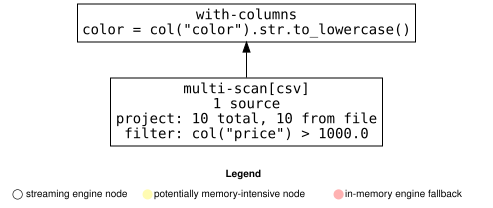

In [40]:
# для картинки нужен Graphviz (программа dot); если его нет — выводим тот же план текстом
try:
    q.show_graph()
except Exception as err:
    print('show_graph недоступен:', type(err).__name__)
    print(q.explain())

In [41]:
%%time

q.collect()

CPU times: user 1.24 s, sys: 307 ms, total: 1.55 s
Wall time: 1.14 s


carat,cut,color,clarity,depth,table,price,'x','y','z'
f64,str,str,str,f64,f64,f64,f64,f64,f64
0.7,"""Ideal""","""e""","""SI1""",62.5,57.0,2757.0,5.7,5.72,3.57
0.86,"""Fair""","""e""","""SI2""",55.1,69.0,2757.0,6.45,6.33,3.52
0.7,"""Ideal""","""g""","""VS2""",61.6,56.0,2757.0,5.7,5.67,3.5
0.71,"""Very Good""","""e""","""VS2""",62.4,57.0,2759.0,5.68,5.73,3.56
0.78,"""Very Good""","""g""","""SI2""",63.8,56.0,2759.0,5.81,5.85,3.72
…,…,…,…,…,…,…,…,…,…
0.72,"""Ideal""","""d""","""SI1""",60.8,57.0,2757.0,5.75,5.76,3.5
0.72,"""Good""","""d""","""SI1""",63.1,55.0,2757.0,5.69,5.75,3.61
0.7,"""Very Good""","""d""","""SI1""",62.8,60.0,2757.0,5.66,5.68,3.56


In [42]:
%%time

q.collect(engine="streaming")   # в Colab: q.collect(streaming=True) — аргумент удалён в polars 2.0

CPU times: user 1.22 s, sys: 313 ms, total: 1.53 s
Wall time: 1.05 s


carat,cut,color,clarity,depth,table,price,'x','y','z'
f64,str,str,str,f64,f64,f64,f64,f64,f64
0.7,"""Ideal""","""e""","""SI1""",62.5,57.0,2757.0,5.7,5.72,3.57
0.86,"""Fair""","""e""","""SI2""",55.1,69.0,2757.0,6.45,6.33,3.52
0.7,"""Ideal""","""g""","""VS2""",61.6,56.0,2757.0,5.7,5.67,3.5
0.71,"""Very Good""","""e""","""VS2""",62.4,57.0,2759.0,5.68,5.73,3.56
0.78,"""Very Good""","""g""","""SI2""",63.8,56.0,2759.0,5.81,5.85,3.72
…,…,…,…,…,…,…,…,…,…
0.72,"""Ideal""","""d""","""SI1""",60.8,57.0,2757.0,5.75,5.76,3.5
0.72,"""Good""","""d""","""SI1""",63.1,55.0,2757.0,5.69,5.75,3.61
0.7,"""Very Good""","""d""","""SI1""",62.8,60.0,2757.0,5.66,5.68,3.56


### Заключение по Polars и Pandas

Нельзя сказать, что Polars во всех запросах сильно выигрывает у Pandas, но благодаря его появлению разработчики выпустили Pandas 2.0 - версию классической библиотеки с привычным синтаксисом, но гораздо более быстрой работой.

Про сравнение Pandas, Polars и Pandas 2.0 можно почитать [здесь](https://medium.com/cuenex/pandas-2-0-vs-polars-the-ultimate-battle-a378eb75d6d1).

### Возвращаемся к исходной таблице

После раздела Polars переменная `df` указывает на «большую» таблицу из `diamonds_big.csv`, где каждая строка повторена 51 раз. Для линейной регрессии такие копии ничего не меняют: у метода наименьших квадратов те же нормальные уравнения, только умноженные на 51. Проверим это и дальше будем работать с исходными 53 805 алмазами, так графики и обучение идут в 51 раз быстрее.

In [43]:
from sklearn.linear_model import LinearRegression

n_big = len(df)
lr_big = LinearRegression().fit(df[['carat']], df['price'])

df = pd.read_csv(DIAMONDS_DATASET)                  # исходные данные
lr_small = LinearRegression().fit(df[['carat']], df['price'])

print('Строк: было', n_big, '→ стало', len(df))
print(f'51 копия: price = {lr_big.intercept_:.4f} + {lr_big.coef_[0]:.4f}·carat')
print(f'исходные: price = {lr_small.intercept_:.4f} + {lr_small.coef_[0]:.4f}·carat')

del df_big, df_pl     # освобождаем память (большие таблицы больше не нужны)

Строк: было 2744055 → стало 53805
51 копия: price = -2249.4447 + 7761.8796·carat
исходные: price = -2249.4447 + 7761.8796·carat


# Введение в машинное обучение (основные понятия)

Основные понятия.

В нашем примере мы можем попробовать предсказать стоимость алмаза по его характеристикам.

* алмазы - *объекты*
* характеристики - *признаки*
* стоимость - *целевая переменная*

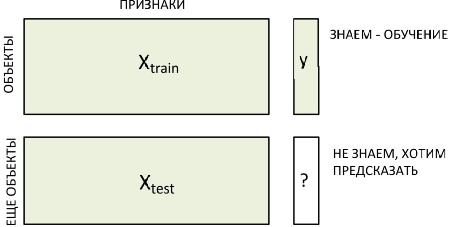

Модели машинного обучения - это некоторые математические правила (обычно функции), по которым модель делает прогноз.

**Пример (линейная регрессия):**

$price = a + b\cdot carat + c\cdot depth,$

здесь $a,b,c$ - параметры модели (заранее мы их не знаем).

*Параметры подбираются по обучающим данным так, чтобы модель ошибалась меньше всего.*

Пример плохо подобранных параметров $a, b$ модели
$$y = a + b\cdot x.$$

На рисунке
$$y = -30 + 7x.$$

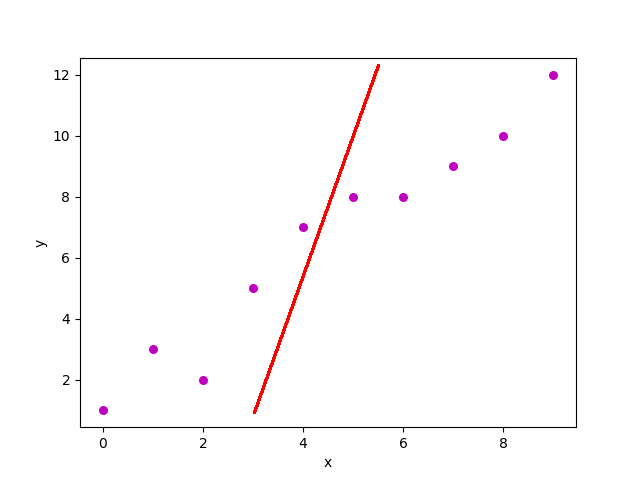

Пример хорошо подобранных параметров:
$$y = 0.5 + x.$$

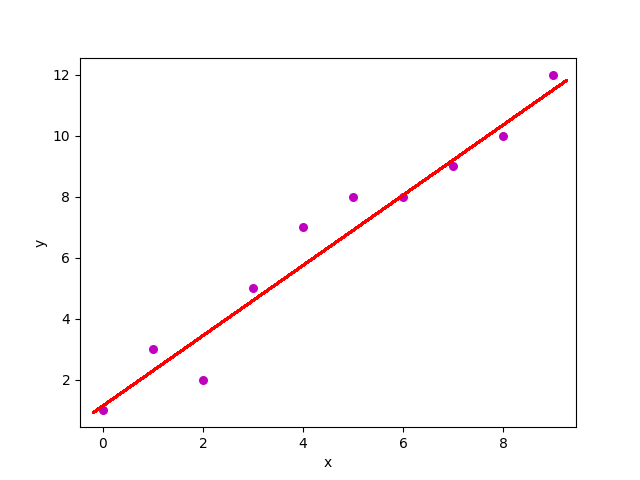

Функции для построения прогнозов бывают разные:

* линейные модели
* решающие правила (если $a$, то $b$)
* нейронные сети
* другие модели

Каждая модель хорошо работает в своих предположениях о данных, поэтому изучить распределение целевой переменной всегда очень полезно.

Обучим линейную регрессию предсказывать цену по числу карат.

In [44]:
X = df[['carat']] # матрица объект-признак
y = df['price'] # целевая переменная

In [45]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X, y)

pred = lr.predict(X)

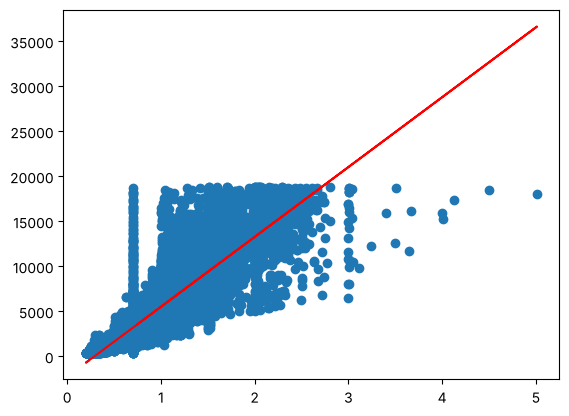

In [46]:
plt.scatter(X.values, y)
plt.plot(X.values, pred, c='red')

Вычислим ошибку модели

$$MAE = \frac1l\sum_{i=1}^l |a(x_i)-y_i|$$

In [47]:
from sklearn.metrics import mean_absolute_error

mean_absolute_error(y, pred)

1025.6549394439717

In [48]:
np.mean(y)

np.float64(3933.562828733389)

## Анализ распределения столбцов (целевой переменной)

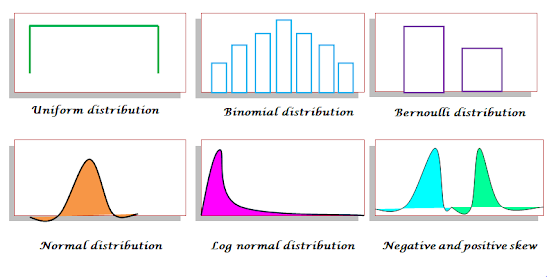

В основном в задачах регрессии мы ожидаем увидеть нормально распределенную целевую переменную. Многие модели заточены под нормальное распределение.

Но не только в этом дело...

<Axes: xlabel='price', ylabel='Count'>

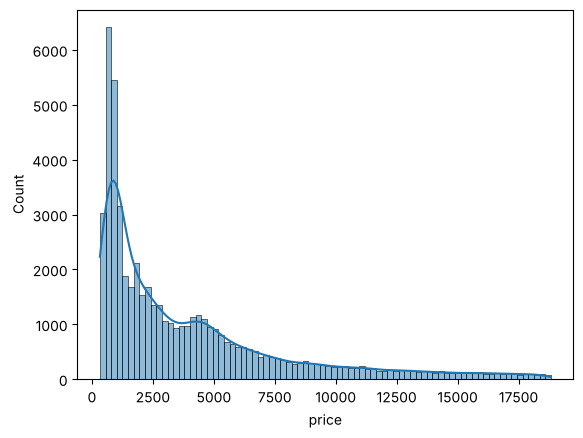

In [49]:
sns.histplot(data = df['price'], kde = True)

<Axes: xlabel='price', ylabel='Count'>

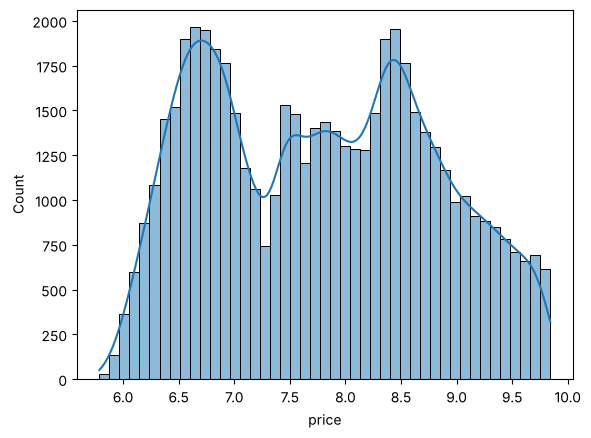

In [50]:
sns.histplot(data = np.log(df['price']), kde = True)

Мы видим у распределения тяжелый хвост, который может быть трудно прогнозируем моделями (так как там мало значений).

Проверим это.

In [51]:
mean_absolute_error(y[y < 10000], pred[y < 10000])

812.9520456476465

In [52]:
mean_absolute_error(y[y >= 10000], pred[y >= 10000])

3010.432690945509

Действительно, ошибка на дорогих алмазах больше.

In [53]:
X2 = df[['carat']]
y2 = df['depth']

lr = LinearRegression()
lr.fit(X2, y2)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.09]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['carat']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,61.68
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [54]:
pred_depth = lr.predict(X2)

mean_absolute_error(y2, pred_depth), np.mean(y2)

(1.0076869801160742, np.float64(61.74927980670942))

<Axes: xlabel='depth', ylabel='Count'>

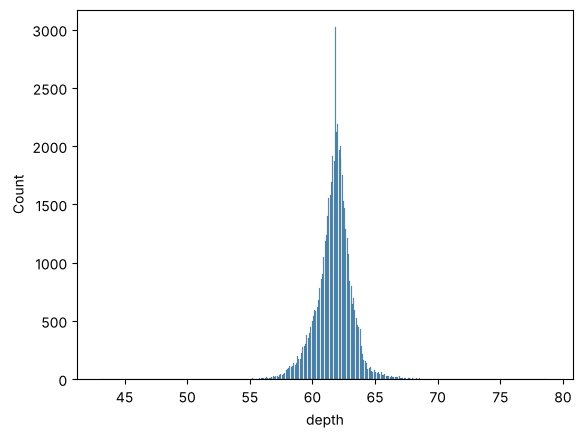

In [55]:
sns.histplot(df.depth)

In [56]:
len(y2[y2<60])/len(y2) # доля выборки

0.09287240962735806

In [57]:
mean_absolute_error(y2[y2<60], pred_depth[y2<60])

2.7813253243166725

In [58]:
len(y2[(y2 >= 60) & (y2 <= 63)])/len(y2) # доля выборки

0.7785335935321996

In [59]:
mean_absolute_error(y2[(y2 >= 60) & (y2 <= 63)], pred_depth[(y2 >= 60) & (y2 <= 63)])

0.6017471857996337

## Задание 4

Будем решать задачу прогноза стоимости алмаза по его параметру `table`.

Обучите линейную регрессию для решения этой задачи и выведите на экран ошибку MAE.

price ≈ -9059.4 + 226.13·table
MAE (table):                 2989.02
MAE (константа = среднее):   3031.21
MAE (carat, модель выше):    1025.65


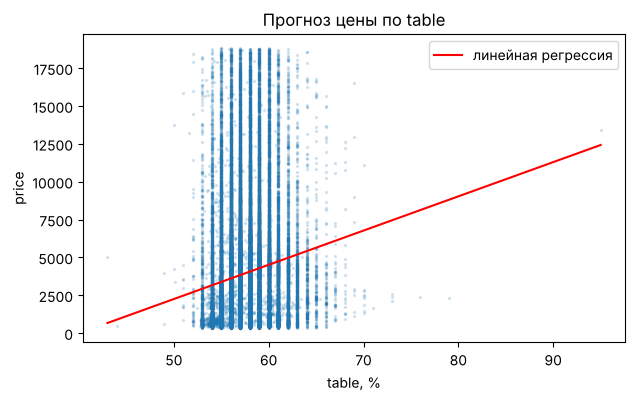

In [60]:
X_table = df[['table']]
y = df['price']

lr_table = LinearRegression()
lr_table.fit(X_table, y)
pred_table = lr_table.predict(X_table)

mae_table = mean_absolute_error(y, pred_table)
mae_const = mean_absolute_error(y, np.full(len(y), y.mean()))   # для сравнения: всегда предсказывать среднее
print(f'price ≈ {lr_table.intercept_:.1f} + {lr_table.coef_[0]:.2f}·table')
print('MAE (table):                ', round(mae_table, 2))
print('MAE (константа = среднее):  ', round(mae_const, 2))
print('MAE (carat, модель выше):   ', round(mean_absolute_error(y, pred), 2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df['table'], y, s=2, alpha=0.15)
grid = np.linspace(df['table'].min(), df['table'].max(), 100)
ax.plot(grid, lr_table.intercept_ + lr_table.coef_[0] * grid, c='red', label='линейная регрессия')
ax.set(xlabel='table, %', ylabel='price', title='Прогноз цены по table'); ax.legend()
plt.show()

**Ответ: MAE = 2989.02.**

Модель: price ≈ −9059.4 + 226.13·table. На графике прямая проходит почти горизонтально через середину облака, потому что линейная связь `table` с ценой слабая (r = 0.13). Для сравнения, если всегда предсказывать среднюю цену, MAE = 3031.21, так что `table` почти ничего не добавляет к такому прогнозу (выигрыш 1.4 %). Модель по `carat` ошибается втрое меньше (1025.65).

## Задание 5

Сколько процентов от среднего значения `price` составляет ошибка?

In [61]:
mae_pct = 100 * mae_table / y.mean()
print(f'Средняя цена: {y.mean():.2f}; MAE = {mae_table:.2f} — это {mae_pct:.2f} % от средней цены')

Средняя цена: 3933.56; MAE = 2989.02 — это 75.99 % от средней цены


**Ответ: ≈ 76 %** (75.99 %). В среднем прогноз по `table` ошибается на три четверти средней цены алмаза, и для практики такая точность бесполезна.

## Задание 6

Вычислите ошибку MAE для алмазов маленькой и большой стоимости отдельно:

* `price` < 10_000
* `price` >= 10_000

Какая из ошибок больше?

Как вы думаете почему?

Больше ошибка для дорогих алмазов
98 % прогнозов лежат в диапазоне [2925. 5413.]


,алмазов,доля выборки,средняя цена,средний прогноз,MAE,MAE / средняя цена,доля заниженных прогнозов
price < 10 000,48597,0.903,2893.333,3923.050,2279.627,0.788,0.283
price ≥ 10 000,5208,0.097,13640.180,4031.659,9608.520,0.704,1.000


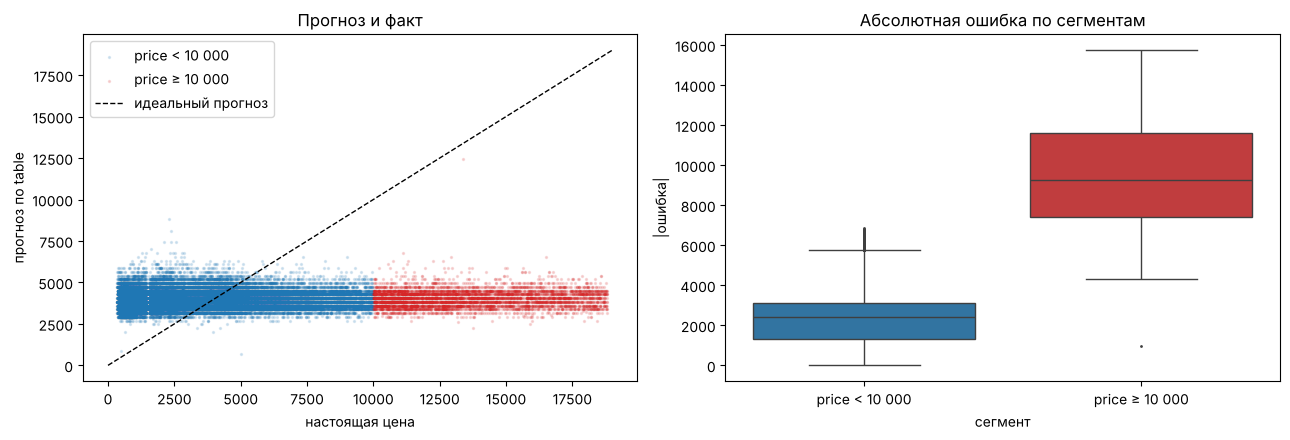

In [62]:
low = y < 10_000
high = y >= 10_000

mae_low = mean_absolute_error(y[low], pred_table[low])
mae_high = mean_absolute_error(y[high], pred_table[high])

seg = pd.DataFrame({
    'алмазов': [low.sum(), high.sum()],
    'доля выборки': [low.mean(), high.mean()],
    'средняя цена': [y[low].mean(), y[high].mean()],
    'средний прогноз': [pred_table[low].mean(), pred_table[high].mean()],
    'MAE': [mae_low, mae_high],
    'MAE / средняя цена': [mae_low / y[low].mean(), mae_high / y[high].mean()],
    'доля заниженных прогнозов': [(pred_table[low] < y[low]).mean(), (pred_table[high] < y[high]).mean()],
}, index=['price < 10 000', 'price ≥ 10 000']).round(3)
print('Больше ошибка для', 'дорогих' if mae_high > mae_low else 'дешёвых', 'алмазов')
print('98 % прогнозов лежат в диапазоне', np.percentile(pred_table, [1, 99]).round(0))
display(seg)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y[low], pred_table[low], s=2, alpha=0.15, label='price < 10 000')
axes[0].scatter(y[high], pred_table[high], s=2, alpha=0.15, c='tab:red', label='price ≥ 10 000')
axes[0].plot([0, 19000], [0, 19000], 'k--', lw=1, label='идеальный прогноз')
axes[0].set(xlabel='настоящая цена', ylabel='прогноз по table', title='Прогноз и факт'); axes[0].legend()
abs_err = pd.DataFrame({'|ошибка|': np.abs(y - pred_table),
                        'сегмент': np.where(high, 'price ≥ 10 000', 'price < 10 000')})
sns.boxplot(data=abs_err, x='сегмент', y='|ошибка|', hue='сегмент', palette=['tab:blue', 'tab:red'],
            legend=False, fliersize=1, ax=axes[1])
axes[1].set_title('Абсолютная ошибка по сегментам')
plt.tight_layout(); plt.show()

**Ответ: больше ошибка на дорогих алмазах.** MAE = 9608.52 для `price ≥ 10 000` против 2279.63 для `price < 10 000`, то есть примерно в 4.2 раза.

Почему так получается, по таблице и графикам:

* Модель по `table` почти не различает алмазы: 98 % её прогнозов лежат в узком коридоре около 2900–5400, рядом со средней ценой 3934. По сути она предсказывает «типичную» цену.
* Дорогих алмазов мало (9.7 % выборки), и они лежат в длинном правом хвосте распределения цены, далеко от этой типичной цены (в среднем 13 640). Средний прогноз для них около 4032, и все 100 % этих камней модель недооценивает, отсюда огромная абсолютная ошибка.
* Метод наименьших квадратов подгоняет прямую под основную массу данных, то есть под дешёвые камни (90 %). Хвост, которого в выборке мало, на неё почти не влияет, и об этом говорилось выше на примере модели по `carat`.
* В относительных величинах картина не такая разная: MAE / средняя цена 0.79 для дешёвых и 0.70 для дорогих. Модель одинаково плоха везде, а большая абсолютная ошибка на дорогих камнях отражает то, что сама цена у них в разы выше.

## Итоги практики

| Задание | Ответ |
|---|---|
| 1. С чем сильнее всего коррелирует `depth` (Кендалл) | **`table`** (τ = −0.177 по модулю; среди положительных `'z'`, 0.071) |
| 2. Фильтр `color = "J"`, `price > 1000`: pandas vs polars | 119 493 строки в обоих; **polars быстрее ≈ в 8.7 раза (22.5 мс против 194.7 мс)** |
| 3. Медиана цены и средний вес по цвету: eager vs lazy | таблицы совпадают; **polars быстрее pandas ≈ в 2.0 раза (eager) и в 3.0 раза (lazy)** |
| 4. MAE линейной регрессии `price ~ table` | **2989.02** |
| 5. MAE в процентах от средней цены | **≈ 76 %** (75.99 %) |
| 6. MAE для `price < 10 000` / `≥ 10 000` | **2279.63 / 9608.52**: больше на дорогих (почти постоянный прогноз + длинный хвост цен) |

Дополнительно: V Крамера между `cut`, `color`, `clarity` от 0.04 до 0.14 (слабая связь). ANOVA находит статистически значимые различия средних во всех 21 паре, но размер эффекта η² для цены всего 0.01–0.03, а заметный эффект только у `cut` → `table` (0.32).